# 3 Miscellaneous figures

Figures of the paper without data behind them, and the two figures that explain Monte Carlo dropout with the draws of one window (stored in `results/stage2/mc_window_draws.npz`, see notebook 0). The pipeline overview (Fig. 3) was drawn by hand and is not included.

Figs. 5, 6, 8 and 9 are drawn as SVG and saved as PNG. Their versions in the paper were edited by hand afterwards, so the layout differs slightly from the paper. Figures are written to `outputs/3_miscellaneous_figures/`.

With `RESULTS = 'retrained'`, Figs. 8 and 9 use the draws of notebook 0 in `results_retrained/` instead, and the figures are written to `outputs_retrained/`.

In [1]:
%matplotlib inline
import numpy as np
from IPython.display import Image, display

from two_stage import config as cfg, plots, schematics

RESULTS = 'paper'

cfg.use_results(RESULTS)
OUT = cfg.figure_dir('3_miscellaneous_figures')

**Paper, Fig. 1.** A healthy and an anomalous time series of the dataset.

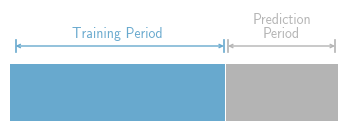

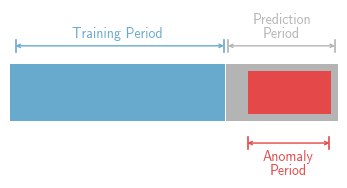

In [2]:
for anomaly, name in ((False, 'fig01a_healthy_time_series'), (True, 'fig01b_anomalous_time_series')):
    fig = plots.care_period(anomaly)
    plots.save(fig, OUT / name)

**Paper, Fig. 2.** The generated RUL label.

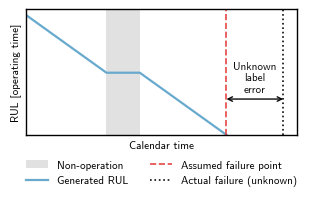

In [3]:
fig = plots.rul_label()
plots.save(fig, OUT / 'fig02_rul_label')

**Paper, Figs. 5 and 6.** The component specialization methods.

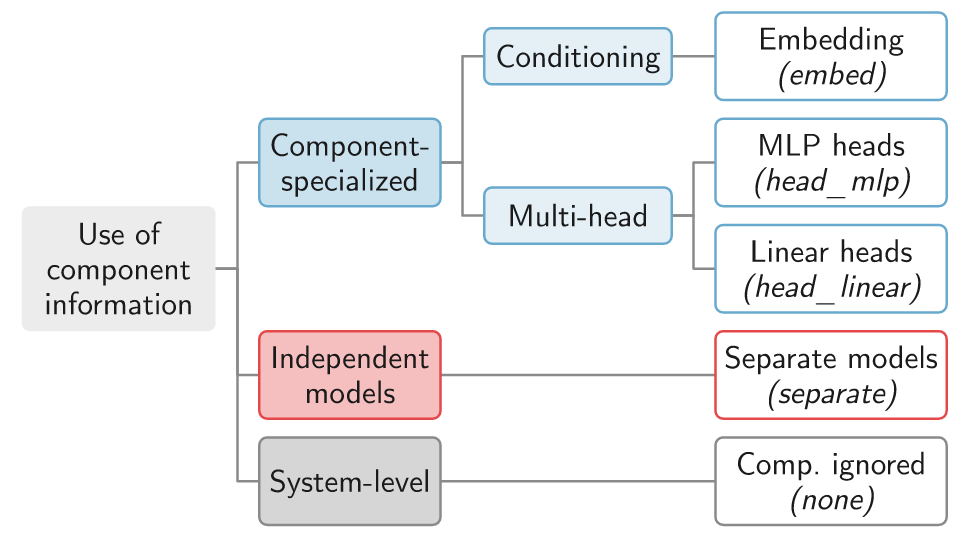

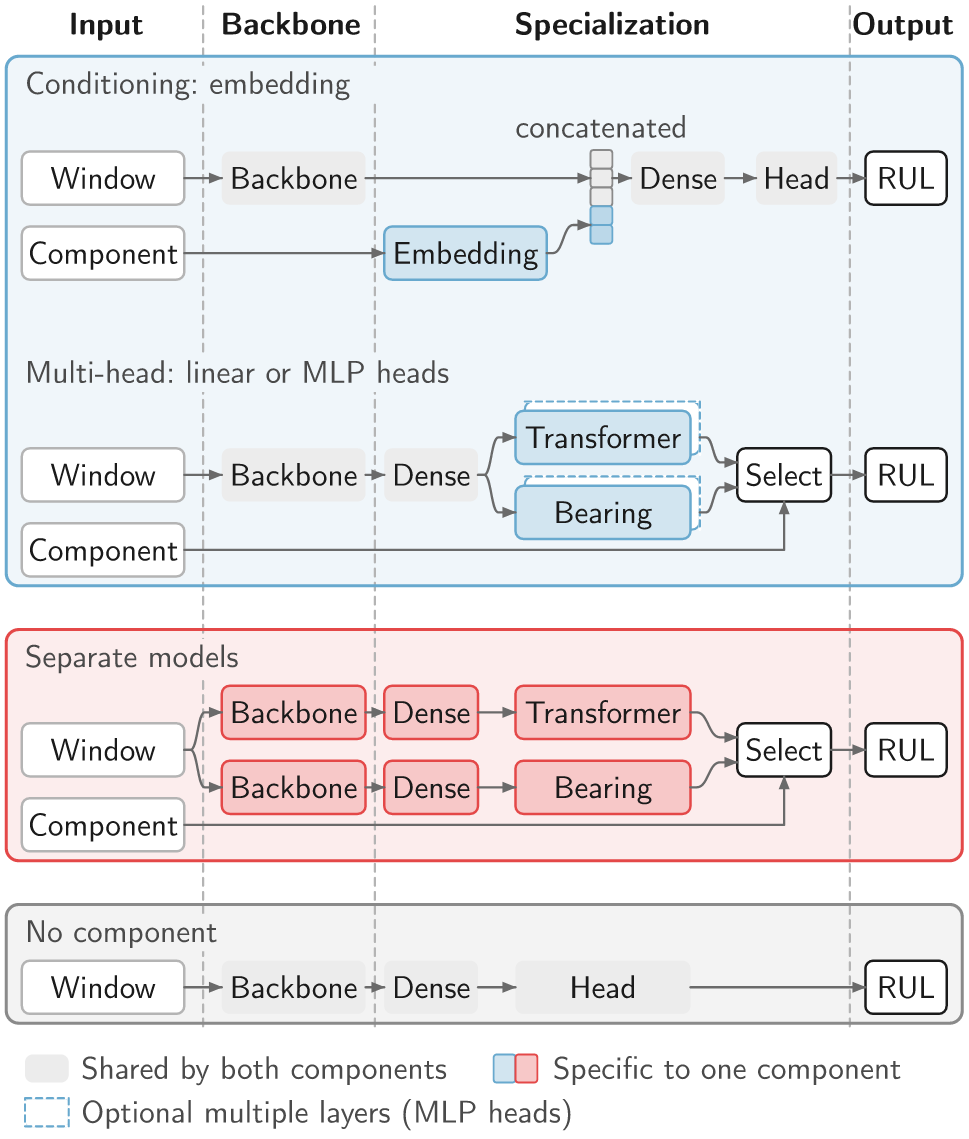

In [4]:
for drawing, name in ((schematics.specialization_tree(), 'fig05_specialization_methods'),
                      (schematics.specialization_models(), 'fig06_specialization_models')):
    display(Image(filename=drawing.save(OUT / name), width=600))

**Paper, Figs. 8 and 9.** Monte Carlo dropout for one network, and the pooled distribution of a three-network ensemble.

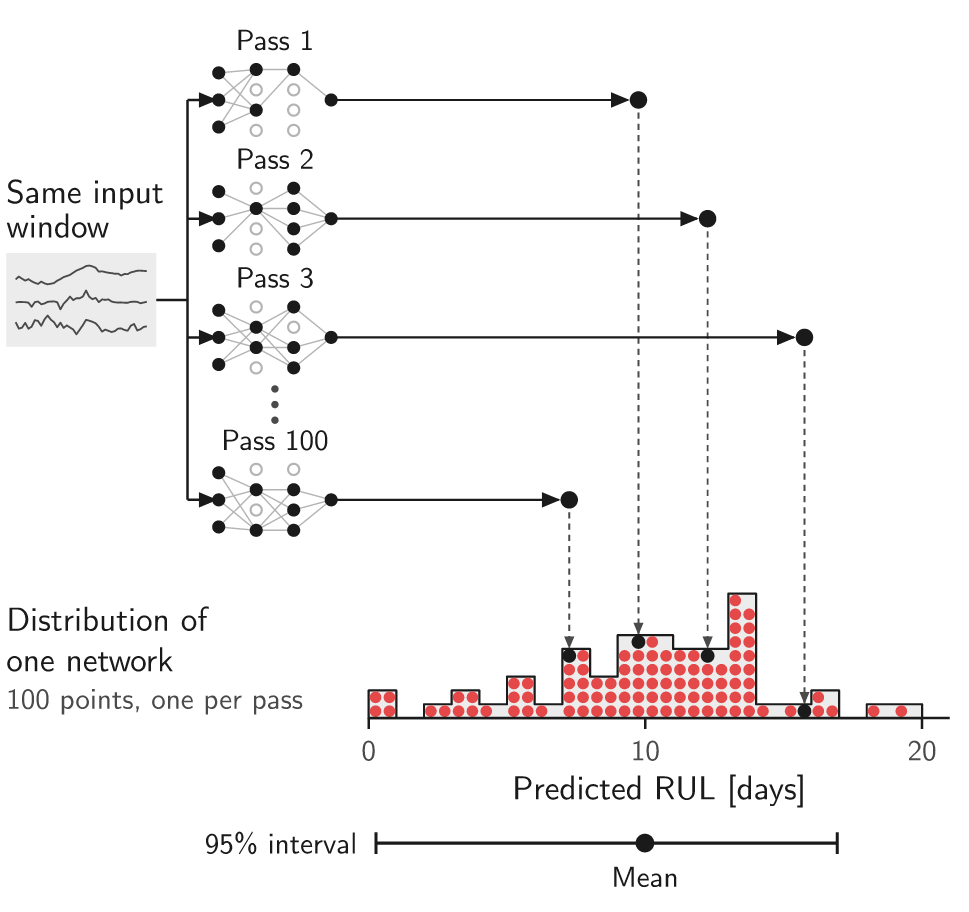

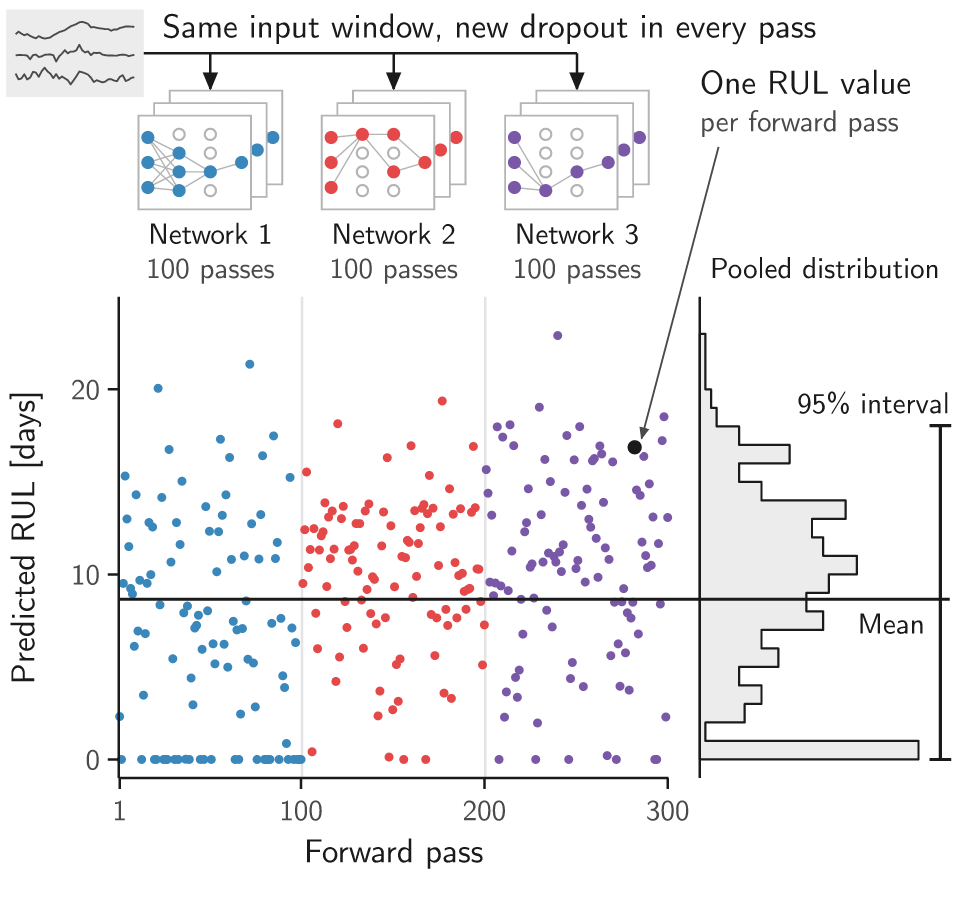

In [5]:
draws = np.load(cfg.result_path('stage2', 'mc_window_draws.npz'))
for drawing, name in ((schematics.mc_dropout_single(draws['draws'], draws['window']), 'fig08_mc_dropout_single_network'),
                      (schematics.mc_dropout_ensemble(draws['draws'], draws['window'], float(draws['point'])),
                       'fig09_mc_dropout_ensemble')):
    display(Image(filename=drawing.save(OUT / name), width=500))